# 01. EDA исходных данных `raw_data`

Данный notebook посвящён первичному исследованию исходных данных проекта.  
Его задача — описать структуру каталога `raw_data/`, проверить согласованность доступных модальностей и зафиксировать правила, по которым данные будут переданы в следующий этап исследования.

Результаты этой части используются в notebook `02_multirate_baseline_raw_data.ipynb`, где уже строится baseline-пайплайн для multi-rate представления данных.

## Цель notebook

Основная цель — получить воспроизводимое описание исходного датасета и определить минимальный набор решений, необходимых для дальнейшей обработки данных.

В рамках EDA рассматриваются:

- структура workload-экспериментов;
- наличие и согласованность логов и KPI-файлов;
- временное разрешение KPI-метрик;
- возможные окна агрегации для multi-rate режима;
- provenance исходных файлов и артефактов анализа.

Notebook не выполняет финальную подготовку train-ready датасета и не обучает модели.

## Логика исследования

Анализ построен последовательно: от общей структуры данных к формальным правилам передачи данных в следующий notebook.

1. **Анатомия датасета**  
   Определение workload-структуры и базовой единицы наблюдения.

2. **Логовая модальность**  
   Проверка наличия и структуры файлов, связанных с логами выполнения.

3. **KPI-модальность**  
   Анализ состава KPI-файлов и доступных системных метрик.

4. **Временное разрешение**  
   Оценка частоты наблюдений и выбор кандидатов окон агрегации.

5. **Аудит provenance**  
   Фиксация происхождения файлов и контроль воспроизводимости.

6. **Политика передачи в notebook 02**  
   Формализация правил, которые будут использоваться на следующем этапе.

In [11]:
from pathlib import Path
from collections import Counter
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


# Настройки отображения и визуального стиля
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)

sns.set_theme(style="whitegrid", context="notebook")


# Базовые пути проекта
START_DIR = Path.cwd().resolve()


def find_project_root(start_dir: Path) -> Path:
    """Находит корень проекта по наличию каталога raw_data."""
    for path in [start_dir, *start_dir.parents]:
        if (path / "raw_data").is_dir():
            return path
    return start_dir


PROJECT_ROOT = find_project_root(START_DIR)
RAW_ROOT = PROJECT_ROOT / "raw_data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "raw_eda"

if not RAW_ROOT.is_dir():
    raise FileNotFoundError(f"Не найден каталог исходных данных: {RAW_ROOT}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Константы исследования
EXPECTED_KPI_METRICS = {
    "cpustat",
    "iostat",
    "jvms",
    "memstat",
    "netstat",
    "vmstat",
}

WINDOW_SECONDS = [10, 30, 60, 300]
KPI_HEAD_TS_SAMPLE = 160


# Контекст выполнения notebook
context_df = pd.DataFrame(
    [
        {"Объект": "Рабочая директория", "Путь": str(START_DIR)},
        {"Объект": "Корень проекта", "Путь": str(PROJECT_ROOT)},
        {"Объект": "Исходные данные", "Путь": str(RAW_ROOT)},
        {"Объект": "Выходные артефакты", "Путь": str(OUTPUT_DIR)},
    ]
)

context_df

,Объект,Путь
0,Рабочая директория,C:\Main\DGTU\ВКР\Diploma\lcman
1,Корень проекта,C:\Main\DGTU\ВКР\Diploma
2,Исходные данные,C:\Main\DGTU\ВКР\Diploma\raw_data
3,Выходные артефакты,C:\Main\DGTU\ВКР\Diploma\outputs\raw_eda



## Implementation helpers

Функции сгруппированы в notebook, чтобы сохранить воспроизводимость clean run без выноса в отдельный модуль.


In [14]:

def safe_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []
    return sorted([p for p in path.iterdir() if p.is_dir() and not p.name.startswith('.')], key=lambda p: p.name)


def safe_files(path: Path, pattern='*'):
    if not path.exists() or not path.is_dir():
        return []
    return sorted([p for p in path.glob(pattern) if p.is_file() and not p.name.startswith('.')], key=lambda p: p.name)


def classify_scenario(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    return 'normal' if name.startswith('normal') else 'failure'


def failure_family(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    if name.startswith('normal'):
        return 'normal'
    if 'cpu' in name:
        return 'cpu'
    if 'memory' in name or 'mem' in name or name == 'vm_stress' or 'vm_' in name:
        return 'memory'
    if 'io' in name:
        return 'io'
    if 'net' in name or 'lose_package' in name or 'mq' in name:
        return 'network'
    if 'datanode' in name:
        return 'datanode'
    if 'namenode' in name:
        return 'namenode'
    if 'nodemanager' in name:
        return 'nodemanager'
    if 'resourcemanager' in name:
        return 'resourcemanager'
    if 'master' in name:
        return 'master'
    if 'worker' in name:
        return 'worker'
    if 'late' in name or 'slow' in name:
        return 'timing'
    if 'killed' in name:
        return 'killed_other'
    if 'suspended' in name:
        return 'suspended_other'
    return 'other'


def failure_mode(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    if name.startswith('normal'):
        return 'normal'
    if 'killed' in name:
        return 'killed'
    if 'suspended' in name:
        return 'suspended'
    if 'stress' in name:
        return 'stress'
    if 'delay' in name:
        return 'delay'
    if 'late' in name:
        return 'late_sub'
    if 'lose' in name:
        return 'packet_loss'
    return 'other'


def compact_display(df: pd.DataFrame, n: int = 12):
    if df is None or len(df) == 0:
        display(pd.DataFrame())
        return
    display(df.head(n))


def require_columns(df: pd.DataFrame, required: list, df_name: str):
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f'{df_name}: отсутствуют обязательные колонки {missing}')


def persist_csv(df: pd.DataFrame, filename: str, artifacts: list):
    path = OUTPUT_DIR / filename
    out = df.copy()
    for col in out.columns:
        dtype = out[col].dtype
        if pd.api.types.is_datetime64_any_dtype(dtype) or isinstance(dtype, pd.DatetimeTZDtype):
            out[col] = out[col].astype(str)
    out.to_csv(path, index=False, encoding='utf-8')
    artifacts.append({
        'artifact': filename,
        'rows': int(len(out)),
        'columns': int(len(out.columns)),
        'path': str(path.relative_to(PROJECT_ROOT))
    })


RAW_LOG_RE = re.compile(r'^(?P<date>\d{2}/\d{2}/\d{2})\s+(?P<time>\d{2}:\d{2}:\d{2})\s+(?P<level>[A-Z]+)\s+(?P<component>[^:]+):\s*(?P<message>.*)$')


def parse_raw_log_line(line: str):
    m = RAW_LOG_RE.match(line.strip())
    if not m:
        return None
    ts = pd.to_datetime(f"{m.group('date')} {m.group('time')}", format='%y/%m/%d %H:%M:%S', utc=True, errors='coerce')
    if pd.isna(ts):
        return None
    return ts, m.group('level'), m.group('component'), m.group('message')


def extract_timestamp_from_parts(parts):
    if len(parts) < 2:
        return None
    if parts[0] == 'HostName' or parts[1] == 'TimeStamp':
        return None
    try:
        ts = float(parts[1])
        return ts if ts > 0 else None
    except Exception:
        return None


def read_tail_lines(path: Path, chunk_size: int = 65536):
    try:
        with path.open('rb') as f:
            f.seek(0, os.SEEK_END)
            end = f.tell()
            if end == 0:
                return []
            offset = max(0, end - chunk_size)
            f.seek(offset)
            data = f.read().decode('utf-8', errors='ignore')
        lines = data.splitlines()
        return lines[1:] if offset > 0 and lines else lines
    except OSError:
        return []


artifacts = []


## 1. Анатомия датасета

На первом этапе проводится инвентаризация каталога `raw_data/`.  
Цель раздела — определить, какие workload и run представлены в данных, а также проверить наличие основных источников:

- `mapred_logs/`;
- `parsed_log/`;
- `kpis/`.

Базовой единицей наблюдения считается пара:

```text
run_id = workload / scenario

In [16]:
### Code cell 1 — расчёт инвентаризации


def scan_raw_data_inventory(raw_root: Path):
    workload_rows = []
    run_rows = []
    issue_rows = []

    for wdir in safe_dirs(raw_root):
        workload = wdir.name

        parsed_dir = wdir / "parsed_log"
        mapred_dir = wdir / "mapred_logs"
        kpis_dir = wdir / "kpis"

        has_labeled = (parsed_dir / "labeled.csv").exists()
        has_normal = (parsed_dir / "normal.csv").exists()
        has_tasks = (parsed_dir / "tasks.csv").exists()

        mapred_logs = {p.stem: p for p in safe_files(mapred_dir, "*.log")}
        kpi_dirs = {p.name: p for p in safe_dirs(kpis_dir)}

        scenario_names = sorted(set(mapred_logs) | set(kpi_dirs))

        required_sources = {
            "mapred_logs/": mapred_dir.exists(),
            "parsed_log/": parsed_dir.exists(),
            "kpis/": kpis_dir.exists(),
            "parsed_log/labeled.csv": has_labeled,
        }

        for source_name, exists in required_sources.items():
            if not exists:
                issue_rows.append(
                    {
                        "level": "workload",
                        "workload": workload,
                        "scenario": None,
                        "issue": f"missing {source_name}",
                    }
                )

        for scenario in scenario_names:
            kpi_dir = kpi_dirs.get(scenario)
            instruments_dir = kpi_dir / "instruments" if kpi_dir else None

            host_dirs = safe_dirs(instruments_dir) if instruments_dir else []

            metric_names = set()
            instrument_files = 0

            for host_dir in host_dirs:
                for file_path in safe_files(host_dir):
                    metric_names.add(file_path.name)
                    instrument_files += 1

            has_mapred_log = scenario in mapred_logs
            has_kpi_dir = scenario in kpi_dirs
            has_kpi_measurements = instrument_files > 0

            if has_mapred_log and not has_kpi_dir:
                issue_rows.append(
                    {
                        "level": "run",
                        "workload": workload,
                        "scenario": scenario,
                        "issue": "mapred without kpi directory",
                    }
                )

            if has_kpi_dir and not has_mapred_log:
                issue_rows.append(
                    {
                        "level": "run",
                        "workload": workload,
                        "scenario": scenario,
                        "issue": "kpi directory without mapred",
                    }
                )

            if has_kpi_dir and not has_kpi_measurements:
                issue_rows.append(
                    {
                        "level": "run",
                        "workload": workload,
                        "scenario": scenario,
                        "issue": "kpi directory without measurements",
                    }
                )

            run_rows.append(
                {
                    "workload": workload,
                    "scenario": scenario,
                    "run_id": f"{workload}/{scenario}",
                    "scenario_type": classify_scenario(scenario),
                    "failure_family": failure_family(scenario),
                    "failure_mode": failure_mode(scenario),
                    "has_mapred_log": has_mapred_log,
                    "has_kpi_dir": has_kpi_dir,
                    "has_kpi_measurements": has_kpi_measurements,
                    "has_parsed_labeled_workload": has_labeled,
                    "has_parsed_normal_workload": has_normal,
                    "has_parsed_tasks_workload": has_tasks,
                    "host_count": len(host_dirs),
                    "metric_count": len(metric_names),
                    "instrument_files": instrument_files,
                    "strict_path_pair": (
                        has_mapred_log
                        and has_kpi_dir
                        and has_kpi_measurements
                    ),
                }
            )

        workload_rows.append(
            {
                "workload": workload,
                "has_labeled_csv": has_labeled,
                "mapred_scenarios": len(mapred_logs),
                "kpi_scenarios": len(kpi_dirs),
                "runs_detected": len(scenario_names),
            }
        )

    dataset_inventory = (
        pd.DataFrame(
            workload_rows,
            columns=[
                "workload",
                "has_labeled_csv",
                "mapred_scenarios",
                "kpi_scenarios",
                "runs_detected",
            ],
        )
        .sort_values("workload")
        .reset_index(drop=True)
    )

    run_inventory = (
        pd.DataFrame(
            run_rows,
            columns=[
                "workload",
                "scenario",
                "run_id",
                "scenario_type",
                "failure_family",
                "failure_mode",
                "has_mapred_log",
                "has_kpi_dir",
                "has_kpi_measurements",
                "has_parsed_labeled_workload",
                "has_parsed_normal_workload",
                "has_parsed_tasks_workload",
                "host_count",
                "metric_count",
                "instrument_files",
                "strict_path_pair",
            ],
        )
        .sort_values(["workload", "scenario"])
        .reset_index(drop=True)
    )

    inventory_issues = pd.DataFrame(
        issue_rows,
        columns=["level", "workload", "scenario", "issue"],
    )

    if not inventory_issues.empty:
        inventory_issues = (
            inventory_issues
            .sort_values(
                ["level", "workload", "scenario", "issue"],
                na_position="first",
            )
            .reset_index(drop=True)
        )

    return dataset_inventory, run_inventory, inventory_issues


dataset_inventory_df, run_inventory_df, inventory_issues_df = scan_raw_data_inventory(RAW_ROOT)

if dataset_inventory_df.empty:
    raise ValueError("Инвентаризация пуста: workload в raw_data не обнаружены.")

if run_inventory_df.empty:
    raise ValueError("Инвентаризация пуста: run_id в raw_data не обнаружены.")


require_columns(
    dataset_inventory_df,
    [
        "workload",
        "has_labeled_csv",
        "mapred_scenarios",
        "kpi_scenarios",
        "runs_detected",
    ],
    "dataset_inventory_df",
)

require_columns(
    run_inventory_df,
    [
        "run_id",
        "scenario_type",
        "failure_family",
        "strict_path_pair",
    ],
    "run_inventory_df",
)

require_columns(
    inventory_issues_df,
    [
        "level",
        "workload",
        "scenario",
        "issue",
    ],
    "inventory_issues_df",
)

### График структуры workload

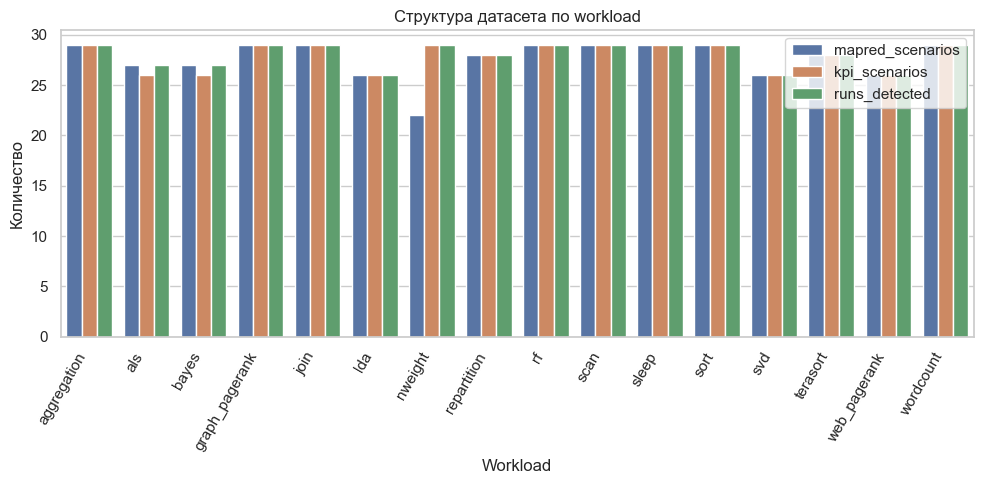

In [43]:
inventory_plot_df = dataset_inventory_df.melt(
    id_vars="workload",
    value_vars=["mapred_scenarios", "kpi_scenarios", "runs_detected"],
    var_name="indicator",
    value_name="value",
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=inventory_plot_df,
    x="workload",
    y="value",
    hue="indicator",
)

plt.title("Структура датасета по workload")
plt.xlabel("Workload")
plt.ylabel("Количество")
plt.xticks(rotation=60, ha="right")
plt.legend(title="")
plt.tight_layout()
plt.show()

In [18]:
run_inventory_preview = run_inventory_df[
    [
        "run_id",
        "scenario_type",
        "failure_family",
        "failure_mode",
        "has_mapred_log",
        "has_kpi_dir",
        "has_kpi_measurements",
        "strict_path_pair",
        "host_count",
        "metric_count",
        "instrument_files",
    ]
]

run_inventory_preview

,run_id,scenario_type,failure_family,failure_mode,has_mapred_log,has_kpi_dir,has_kpi_measurements,strict_path_pair,host_count,metric_count,instrument_files
0,aggregation/2nd_namenode_killed,failure,namenode,killed,True,True,True,True,6,6,36
1,aggregation/2nd_namenode_suspended,failure,namenode,suspended,True,True,True,True,6,6,36
2,aggregation/cpu_stress,failure,cpu,stress,True,True,True,True,6,6,36
3,aggregation/datanode_killed,failure,datanode,killed,True,True,True,True,6,6,36
4,aggregation/datanode_suspended,failure,datanode,suspended,True,True,True,True,6,6,36
...,...,...,...,...,...,...,...,...,...,...,...
444,wordcount/resourcemanager_suspended,failure,resourcemanager,suspended,True,True,True,True,6,6,36
445,wordcount/slow_stress,failure,timing,stress,True,True,True,True,6,6,36
446,wordcount/vm_stress,failure,memory,stress,True,True,True,True,6,6,36
447,wordcount/worker_killed,failure,worker,killed,True,True,True,True,6,6,36


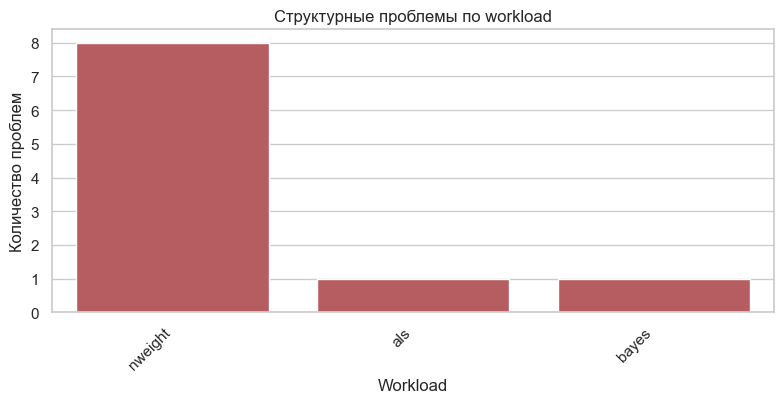

In [44]:
if not inventory_issues_df.empty:
    issues_plot_df = (
        inventory_issues_df
        .groupby("workload", as_index=False)
        .agg(issues=("issue", "count"))
        .sort_values("issues", ascending=False)
    )

    plt.figure(figsize=(8, 4.2))

    sns.barplot(
        data=issues_plot_df,
        x="workload",
        y="issues",
        color="#C44E52",
    )

    plt.title("Структурные проблемы по workload")
    plt.xlabel("Workload")
    plt.ylabel("Количество проблем")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Выводы по разделу

В каталоге `raw_data/` обнаружено **16 workload** и **449 run_id**. В большинстве workload количество сценариев в `mapred_logs/` и `kpis/` совпадает, что подтверждает общую структурную согласованность датасета.

Основные исключения связаны с тремя workload:

- `als`: один сценарий имеет `mapred`-лог, но не имеет соответствующего KPI-каталога;
- `bayes`: один сценарий имеет `mapred`-лог, но не имеет соответствующего KPI-каталога;
- `nweight`: часть сценариев присутствует в KPI-данных, но не имеет соответствующих `mapred`-логов; также для этого workload отсутствует `parsed_log/labeled.csv`.

На уровне `run_id` обнаружено **9 структурных несоответствий** между логовой и KPI-модальностью. При этом основная часть запусков относится к статусу `STRICT`, то есть имеет одновременно `mapred`-лог, KPI-каталог и KPI-измерения.

Таким образом, единица наблюдения


run_id = workload / scenario

## 2. Логовая модальность

В этом разделе анализируется логовая часть исходных данных.  
Логи представлены двумя уровнями:

- `parsed_log/labeled.csv` — workload-level таблица с размеченными шаблонами;
- `mapred_logs/<scenario>.log` — scenario-level raw log для конкретного запуска.

Цель раздела — проверить, насколько полны parsed logs, оценить распределение разметки `Label` и получить краткий паспорт raw logs на уровне запусков.

In [22]:
def load_labeled_logs(raw_root: Path):
    expected_cols = ["Timestamp", "Template", "Content", "Component", "Label"]

    rows = []
    source_rows = []
    issues = []

    for wdir in safe_dirs(raw_root):
        workload = wdir.name
        parsed_dir = wdir / "parsed_log"

        for source_name in ["normal.csv", "tasks.csv", "labeled.csv"]:
            path = parsed_dir / source_name
            source_rows.append(
                {
                    "workload": workload,
                    "source": source_name,
                    "exists": path.exists(),
                }
            )

        labeled_path = parsed_dir / "labeled.csv"

        if not labeled_path.exists():
            issues.append(
                {
                    "workload": workload,
                    "issue": "missing labeled.csv",
                }
            )
            continue

        df = pd.read_csv(labeled_path)

        missing_cols = sorted(set(expected_cols) - set(df.columns))
        if missing_cols:
            issues.append(
                {
                    "workload": workload,
                    "issue": f"missing columns: {missing_cols}",
                }
            )
            continue

        df = df[expected_cols].copy()
        df["workload"] = workload

        df["Timestamp"] = pd.to_numeric(df["Timestamp"], errors="coerce")
        df["Label"] = pd.to_numeric(df["Label"], errors="coerce")

        df["timestamp_dt"] = pd.to_datetime(
            df["Timestamp"],
            unit="s",
            utc=True,
            errors="coerce",
        )

        df["is_marker"] = df["Component"].astype(str).isin(["START", "NORMAL"])

        rows.append(df)

    log_df = (
        pd.concat(rows, ignore_index=True)
        if rows
        else pd.DataFrame(
            columns=expected_cols
            + [
                "workload",
                "timestamp_dt",
                "is_marker",
            ]
        )
    )

    source_df = pd.DataFrame(
        source_rows,
        columns=["workload", "source", "exists"],
    )

    issues_df = pd.DataFrame(
        issues,
        columns=["workload", "issue"],
    )

    return log_df, source_df, issues_df


def compute_log_quality(log_df: pd.DataFrame):
    if log_df.empty:
        return pd.DataFrame(
            columns=[
                "workload",
                "rows",
                "positive_rows",
                "positive_share",
                "timestamp_na",
                "label_na",
                "unique_templates",
                "unique_components",
            ]
        )

    quality_df = (
        log_df
        .groupby("workload", as_index=False)
        .agg(
            rows=("Label", "size"),
            positive_rows=("Label", lambda s: int((s == 1).sum())),
            positive_share=("Label", lambda s: float((s == 1).mean())),
            timestamp_na=("Timestamp", lambda s: int(s.isna().sum())),
            label_na=("Label", lambda s: int(s.isna().sum())),
            unique_templates=("Template", "nunique"),
            unique_components=("Component", "nunique"),
        )
        .sort_values("positive_share", ascending=False)
        .reset_index(drop=True)
    )

    return quality_df


def scan_raw_log_file(path: Path):
    total_lines = 0
    event_lines = 0

    first_ts = None
    last_ts = None

    levels = Counter()

    try:
        with path.open("r", encoding="utf-8", errors="ignore") as file:
            for line in file:
                total_lines += 1

                parsed = parse_raw_log_line(line)
                if parsed is None:
                    continue

                ts, level, _, _ = parsed

                event_lines += 1
                first_ts = ts if first_ts is None or ts < first_ts else first_ts
                last_ts = ts if last_ts is None or ts > last_ts else last_ts
                levels[level] += 1

    except OSError as exc:
        return {
            "parse_error": str(exc),
        }

    duration_sec = (
        (last_ts - first_ts).total_seconds()
        if first_ts is not None and last_ts is not None
        else np.nan
    )

    return {
        "total_lines": total_lines,
        "event_lines": event_lines,
        "event_line_share": event_lines / total_lines if total_lines else np.nan,
        "raw_ts_min": first_ts,
        "raw_ts_max": last_ts,
        "raw_duration_sec": duration_sec,
        "top_levels": json.dumps(dict(levels.most_common(3)), ensure_ascii=False),
        "parse_error": None,
    }


def build_raw_log_passport(raw_root: Path):
    rows = []

    for wdir in safe_dirs(raw_root):
        workload = wdir.name
        mapred_dir = wdir / "mapred_logs"

        for file_path in safe_files(mapred_dir, "*.log"):
            scenario = file_path.stem

            rows.append(
                {
                    "workload": workload,
                    "scenario": scenario,
                    "run_id": f"{workload}/{scenario}",
                    "scenario_type": classify_scenario(scenario),
                    "failure_family": failure_family(scenario),
                    "rel_path": str(file_path.relative_to(PROJECT_ROOT)),
                    **scan_raw_log_file(file_path),
                }
            )

    return pd.DataFrame(
        rows,
        columns=[
            "workload",
            "scenario",
            "run_id",
            "scenario_type",
            "failure_family",
            "rel_path",
            "total_lines",
            "event_lines",
            "event_line_share",
            "raw_ts_min",
            "raw_ts_max",
            "raw_duration_sec",
            "top_levels",
            "parse_error",
        ],
    )

### Расчёт таблиц

In [23]:
log_df, log_source_df, log_issues_df = load_labeled_logs(RAW_ROOT)

parsed_log_availability_df = (
    log_source_df
    .pivot_table(
        index="workload",
        columns="source",
        values="exists",
        aggfunc="max",
    )
    .reset_index()
    .rename_axis(None, axis=1)
)

parsed_log_missing_df = (
    log_source_df
    .loc[~log_source_df["exists"]]
    .sort_values(["workload", "source"])
    .reset_index(drop=True)
)

parsed_log_quality_df = compute_log_quality(log_df)

raw_log_passport_df = build_raw_log_passport(RAW_ROOT)

raw_log_summary_df = (
    raw_log_passport_df
    .groupby("scenario_type", as_index=False)
    .agg(
        runs=("run_id", "count"),
        median_event_line_share=("event_line_share", "median"),
        median_duration_sec=("raw_duration_sec", "median"),
        min_duration_sec=("raw_duration_sec", "min"),
        max_duration_sec=("raw_duration_sec", "max"),
        parse_errors=("parse_error", lambda s: int(s.notna().sum())),
    )
)

raw_log_anomalies_df = (
    raw_log_passport_df
    .loc[
        raw_log_passport_df["parse_error"].notna()
        | raw_log_passport_df["event_line_share"].isna()
        | (raw_log_passport_df["event_line_share"] < 0.5)
    ]
    .sort_values(["workload", "scenario"])
    .reset_index(drop=True)
)


require_columns(
    parsed_log_availability_df,
    ["workload", "labeled.csv", "normal.csv", "tasks.csv"],
    "parsed_log_availability_df",
)

require_columns(
    parsed_log_quality_df,
    [
        "workload",
        "rows",
        "positive_rows",
        "positive_share",
        "timestamp_na",
        "label_na",
        "unique_templates",
        "unique_components",
    ],
    "parsed_log_quality_df",
)

require_columns(
    raw_log_passport_df,
    [
        "run_id",
        "scenario_type",
        "event_line_share",
        "raw_duration_sec",
        "parse_error",
    ],
    "raw_log_passport_df",
)

### heatmap доступности parsed logs

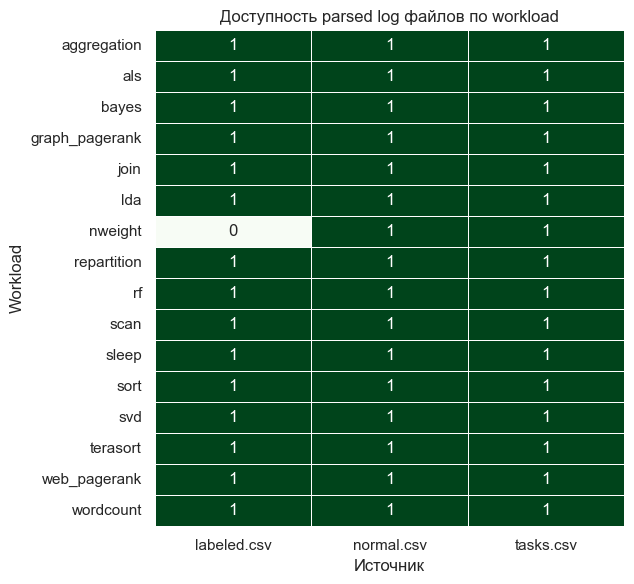

In [45]:
availability_heatmap_df = (
    log_source_df
    .pivot_table(
        index="workload",
        columns="source",
        values="exists",
        aggfunc="max"
    )
    .fillna(False)
    .astype(int)
)

plt.figure(figsize=(6.5, 6))

sns.heatmap(
    availability_heatmap_df,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    linewidths=0.5,
)

plt.title("Доступность parsed log файлов по workload")
plt.xlabel("Источник")
plt.ylabel("Workload")
plt.tight_layout()
plt.show()

### Проблемы parsed logs

In [25]:
parsed_log_missing_df

,workload,source,exists
0,nweight,labeled.csv,False


### Длительность raw logs по типу сценари

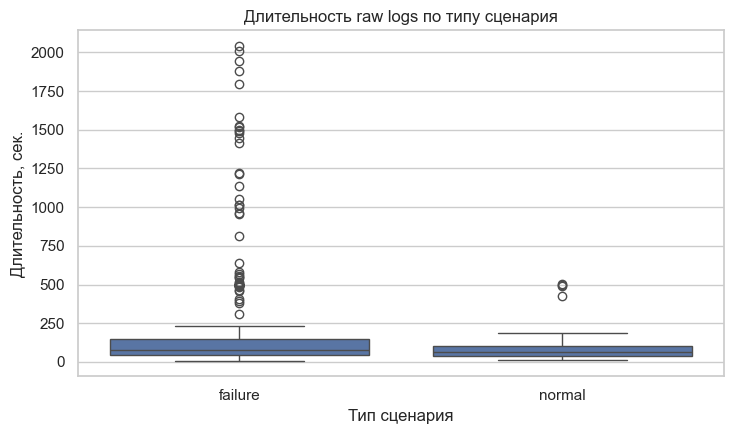

In [47]:
raw_log_duration_plot_df = raw_log_passport_df.dropna(subset=["raw_duration_sec"])

plt.figure(figsize=(7.5, 4.5))

sns.boxplot(
    data=raw_log_duration_plot_df,
    x="scenario_type",
    y="raw_duration_sec",
)

plt.title("Длительность raw logs по типу сценария")
plt.xlabel("Тип сценария")
plt.ylabel("Длительность, сек.")
plt.tight_layout()
plt.show()

### Аномалии raw logs

In [29]:
raw_log_anomalies_view = raw_log_anomalies_df[
    [
        "run_id",
        "scenario_type",
        "failure_family",
        "event_line_share",
        "raw_duration_sec",
        "parse_error",
    ]
]

raw_log_anomalies_view

,run_id,scenario_type,failure_family,event_line_share,raw_duration_sec,parse_error
0,aggregation/datanode_killed,failure,datanode,0.476974,126.0,None
1,lda/cpu_stress,failure,cpu,0.440000,28.0,None
2,lda/datanode_suspended,failure,datanode,0.313514,9.0,None
3,lda/io_stress,failure,io,0.254902,9.0,None
4,lda/late_sub,failure,timing,0.474359,15.0,None
5,lda/memory_stress,failure,memory,0.271429,10.0,None
6,lda/mq_stress,failure,network,0.484277,26.0,None
7,lda/net_delay,failure,network,0.298429,9.0,None
8,lda/net_killed,failure,network,0.000000,NaN,None
9,lda/nodemanager_killed,failure,nodemanager,0.105263,26.0,None


### Распределение доли Label=1

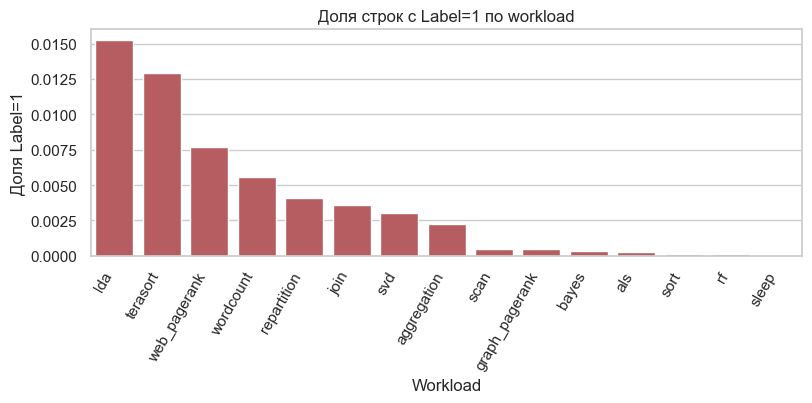

In [30]:
plt.figure(figsize=(8.2, 4.2))

sns.barplot(
    data=parsed_log_quality_df,
    x="workload",
    y="positive_share",
    color="#C44E52",
)

plt.title("Доля строк с Label=1 по workload")
plt.xlabel("Workload")
plt.ylabel("Доля Label=1")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()

### Выводы по разделу

`parsed_log/labeled.csv` доступен почти для всех workload. Исключением является `nweight`, для которого данный файл отсутствует. При этом остальные parsed log источники представлены, поэтому проблема носит локальный характер и должна учитываться отдельно.

Таблица качества показывает, что пропусков в ключевых полях `Timestamp` и `Label` не обнаружено. Следовательно, `labeled.csv` можно использовать как источник информации о шаблонах логов и базовой разметке на workload-уровне.

Доля строк с `Label=1` во всех workload мала. Это указывает на выраженный дисбаланс классов в parsed logs и ограничивает возможность прямого использования этих строк как полноценного run-level датасета.

Для дальнейшего анализа основным источником run-level логовых признаков следует считать файлы:

```text
mapred_logs/<scenario>.log
А parsed_log/labeled.csv целесообразно использовать как вспомогательный источник: для контроля качества, анализа шаблонов и интерпретации логовой модальности.

## 3. KPI-модальность

В этом разделе анализируется KPI-модальность исходных данных.  
KPI-файлы расположены внутри структуры:

```text
raw_data/<workload>/kpis/<scenario>/instruments/<host>/<metric>

Цель раздела — проверить покрытие KPI-файлов по метрикам, хостам и запускам, а также оценить временное разрешение измерений.
Полный value-level ETL на данном этапе не выполняется: используется облегчённый metadata scan по началу и концу файлов.

In [31]:
def build_kpi_file_index(raw_root: Path):
    rows = []
    issues = []

    for wdir in safe_dirs(raw_root):
        workload = wdir.name
        kpis_dir = wdir / "kpis"

        for scenario_dir in safe_dirs(kpis_dir):
            scenario = scenario_dir.name
            instruments_dir = scenario_dir / "instruments"

            if not instruments_dir.exists():
                issues.append(
                    {
                        "workload": workload,
                        "scenario": scenario,
                        "host": None,
                        "metric": None,
                        "issue": "missing instruments directory",
                    }
                )
                continue

            for host_dir in safe_dirs(instruments_dir):
                host = host_dir.name

                for file_path in safe_files(host_dir):
                    metric = file_path.name
                    expected_metric = metric in EXPECTED_KPI_METRICS

                    if not expected_metric:
                        issues.append(
                            {
                                "workload": workload,
                                "scenario": scenario,
                                "host": host,
                                "metric": metric,
                                "issue": "unexpected metric",
                            }
                        )

                    rows.append(
                        {
                            "workload": workload,
                            "scenario": scenario,
                            "run_id": f"{workload}/{scenario}",
                            "host": host,
                            "metric": metric,
                            "rel_path": str(file_path.relative_to(PROJECT_ROOT)),
                            "size_bytes": file_path.stat().st_size,
                            "expected_metric": expected_metric,
                        }
                    )

    kpi_file_index = pd.DataFrame(
        rows,
        columns=[
            "workload",
            "scenario",
            "run_id",
            "host",
            "metric",
            "rel_path",
            "size_bytes",
            "expected_metric",
        ],
    )

    kpi_file_issues = pd.DataFrame(
        issues,
        columns=["workload", "scenario", "host", "metric", "issue"],
    )

    return kpi_file_index, kpi_file_issues


def kpi_file_metadata(path: Path, max_ts_sample: int = KPI_HEAD_TS_SAMPLE):
    header_cols = None
    sample_ts = []
    header_repeats = 0
    first_data_line_len = None

    try:
        with path.open("r", encoding="utf-8", errors="ignore") as file:
            for line in file:
                stripped = line.strip()

                if not stripped:
                    continue

                parts = stripped.split()

                if parts and parts[0] == "HostName":
                    header_repeats += 1
                    header_cols = header_cols or parts
                    continue

                timestamp = extract_timestamp_from_parts(parts)

                if timestamp is None:
                    continue

                if first_data_line_len is None:
                    first_data_line_len = len(
                        line.encode("utf-8", errors="ignore")
                    )

                sample_ts.append(timestamp)

                if len(sample_ts) >= max_ts_sample:
                    break

    except OSError as exc:
        return {"metadata_error": str(exc)}

    last_ts = None

    for line in reversed(read_tail_lines(path)):
        timestamp = extract_timestamp_from_parts(line.strip().split())

        if timestamp is not None:
            last_ts = timestamp
            break

    first_ts = sample_ts[0] if sample_ts else np.nan

    sample_unique_ts = np.array(sorted(set(sample_ts)))

    if len(sample_unique_ts) > 1:
        diffs = np.diff(sample_unique_ts)
        diffs = diffs[diffs > 0]
        median_interval = float(np.median(diffs)) if len(diffs) else np.nan
    else:
        median_interval = np.nan

    dimension_columns = [
        col
        for col in ["Device:", "IFACE", "DEV", "Filesystem"]
        if header_cols and col in header_cols
    ]

    duration_sec = (
        float(last_ts - first_ts)
        if pd.notna(first_ts) and last_ts is not None
        else np.nan
    )

    approx_rows = np.nan

    if first_data_line_len and first_data_line_len > 0:
        approx_rows = int(path.stat().st_size / first_data_line_len)

    return {
        "header_repeats_in_head_sample": header_repeats,
        "dimension_columns": "|".join(dimension_columns),
        "first_ts": first_ts,
        "last_ts": last_ts,
        "sample_median_interval_sec": median_interval,
        "duration_sec": duration_sec,
        "approx_rows_by_size": approx_rows,
        "metadata_error": None,
    }

### Расчёт KPI-индекса и metadata scan

In [32]:
kpi_file_index_df, kpi_file_issues_df = build_kpi_file_index(RAW_ROOT)

metadata_rows = []

for record in kpi_file_index_df.itertuples(index=False):
    absolute_path = PROJECT_ROOT / record.rel_path
    metadata_rows.append(kpi_file_metadata(absolute_path))

kpi_metadata_df = pd.concat(
    [
        kpi_file_index_df.reset_index(drop=True),
        pd.DataFrame(metadata_rows),
    ],
    axis=1,
)

metadata_defaults = {
    "header_repeats_in_head_sample": np.nan,
    "dimension_columns": None,
    "first_ts": np.nan,
    "last_ts": np.nan,
    "sample_median_interval_sec": np.nan,
    "duration_sec": np.nan,
    "approx_rows_by_size": np.nan,
    "metadata_error": None,
}

for column, default in metadata_defaults.items():
    if column not in kpi_metadata_df.columns:
        kpi_metadata_df[column] = default

kpi_metadata_df["first_dt"] = pd.to_datetime(
    kpi_metadata_df["first_ts"],
    unit="s",
    utc=True,
    errors="coerce",
)

kpi_metadata_df["last_dt"] = pd.to_datetime(
    kpi_metadata_df["last_ts"],
    unit="s",
    utc=True,
    errors="coerce",
)

kpi_metadata_df["duration_min"] = kpi_metadata_df["duration_sec"] / 60


require_columns(
    kpi_file_index_df,
    [
        "run_id",
        "host",
        "metric",
        "rel_path",
        "expected_metric",
    ],
    "kpi_file_index_df",
)

require_columns(
    kpi_metadata_df,
    [
        "run_id",
        "metric",
        "sample_median_interval_sec",
        "duration_sec",
        "metadata_error",
    ],
    "kpi_metadata_df",
)

### Сводка по KPI-метрикам

In [52]:
kpi_metric_summary_df = (
    kpi_metadata_df
    .groupby("metric", as_index=False)
    .agg(
        files=("metric", "size"),
        runs=("run_id", "nunique"),
        hosts=("host", "nunique"),
        median_interval_sec=("sample_median_interval_sec", "median"),
        metadata_errors=("metadata_error", lambda s: int(s.notna().sum())),
    )
    .sort_values(["files", "metric"], ascending=[False, True])
    .reset_index(drop=True)
)

display(kpi_metric_summary_df)

,metric,files,runs,hosts,median_interval_sec,metadata_errors
0,cpustat,2682,447,6,1.0,0
1,iostat,2682,447,6,1.0,0
2,jvms,2682,447,6,1.0,0
3,memstat,2682,447,6,1.0,0
4,netstat,2682,447,6,1.0,0
5,vmstat,2682,447,6,1.0,0
6,pgid,1,1,1,NaN,0


### Нестандартные KPI-файлы

In [36]:
kpi_file_issues_df

,workload,scenario,host,metric,issue
0,web_pagerank,2nd_namenode_killed,worker3,pgid,unexpected metric


### Распределение интервалов дискретизации

In [54]:
interval_distribution_df = (
    kpi_metadata_df
    .loc[
        kpi_metadata_df["expected_metric"]
        & kpi_metadata_df["sample_median_interval_sec"].notna()
    ]
    .groupby("sample_median_interval_sec", as_index=False)
    .agg(files=("rel_path", "count"))
    .rename(columns={"sample_median_interval_sec": "interval_sec"})
    .sort_values("interval_sec")
    .reset_index(drop=True)
)

interval_distribution_df

,interval_sec,files
0,1.0,15969
1,1.5,8
2,2.0,112
3,3.0,3


### Выводы по разделу

В KPI-модальности проиндексировано **16 093 файла**. Основные ожидаемые метрики представлены равномерно: `cpustat`, `iostat`, `jvms`, `memstat`, `netstat` и `vmstat` имеют одинаковое покрытие по числу файлов, запусков и хостов.

Для ожидаемых KPI-метрик медианный интервал дискретизации составляет **1 секунду**. Это означает, что KPI-данные имеют регулярное временное разрешение и могут использоваться для построения признаков в multi-rate режиме.

Ошибок metadata scan для ожидаемых KPI-файлов не обнаружено. Единственное структурное отклонение связано с метрикой `pgid`, найденной в одном запуске:

```text
web_pagerank / 2nd_namenode_killed / worker3 / pgid

На следующем этапе KPI-файлы следует читать не как один плоский CSV, а как набор временных рядов с явной структурой:
run_id / host / metric / series
Такой формат позволяет сохранить различия между хостами, метриками и внутренними измерениями отдельных KPI-файлов.


## 4. Временное разрешение

**Вопрос.** Какие размеры окон согласованы с длительностью run и плотностью KPI-времени?  
**Метод.** Совмещение run-span из raw logs и KPI metadata.  
**Минимальный расчёт.** Для окон `10s`, `30s`, `1min`, `5min` оценивается ожидаемое число окон на run.


In [55]:
raw_span = (
    raw_log_passport_df
    .groupby(["workload", "scenario", "run_id"], as_index=False)
    .agg(
        raw_ts_min=("raw_ts_min", "min"),
        raw_ts_max=("raw_ts_max", "max"),
        raw_duration_sec=("raw_duration_sec", "max"),
    )
)

kpi_span = (
    kpi_metadata_df
    .groupby(["workload", "scenario", "run_id"], as_index=False)
    .agg(
        kpi_ts_min=("first_dt", "min"),
        kpi_ts_max=("last_dt", "max"),
        kpi_duration_sec=("duration_sec", "max"),
        median_file_interval_sec=("sample_median_interval_sec", "median"),
    )
)

run_span_df = (
    run_inventory_df[
        [
            "workload",
            "scenario",
            "run_id",
            "scenario_type",
            "failure_family",
            "strict_path_pair",
        ]
    ]
    .merge(raw_span, on=["workload", "scenario", "run_id"], how="left")
    .merge(kpi_span, on=["workload", "scenario", "run_id"], how="left")
)

run_span_df["combined_start"] = run_span_df[["raw_ts_min", "kpi_ts_min"]].min(axis=1)
run_span_df["combined_end"] = run_span_df[["raw_ts_max", "kpi_ts_max"]].max(axis=1)

run_span_df["combined_duration_sec"] = (
    run_span_df["combined_end"] - run_span_df["combined_start"]
).dt.total_seconds()

run_span_df["best_duration_sec"] = run_span_df[
    ["raw_duration_sec", "kpi_duration_sec", "combined_duration_sec"]
].max(axis=1)

require_columns(
    run_span_df,
    ["run_id", "scenario_type", "failure_family", "best_duration_sec"],
    "run_span_df",
)

report_rows = []

for window_sec in WINDOW_SECONDS:
    n_windows = np.ceil(run_span_df["best_duration_sec"].clip(lower=0) / window_sec)

    report_rows.append(
        {
            "window_sec": window_sec,
            "window_label": f"{window_sec}s" if window_sec < 60 else f"{window_sec // 60}min",
            "median_windows_per_run": float(np.nanmedian(n_windows)),
            "q95_windows_per_run": (
                float(np.nanpercentile(n_windows.dropna(), 95))
                if n_windows.notna().any()
                else np.nan
            ),
            "share_single_window": float((n_windows <= 1).mean()),
            "runs_with_duration": int(run_span_df["best_duration_sec"].notna().sum()),
        }
    )

window_resolution_report_df = pd.DataFrame(report_rows)

require_columns(
    window_resolution_report_df,
    [
        "window_sec",
        "window_label",
        "median_windows_per_run",
        "q95_windows_per_run",
        "share_single_window",
        "runs_with_duration",
    ],
    "window_resolution_report_df",
)

### График длительности run

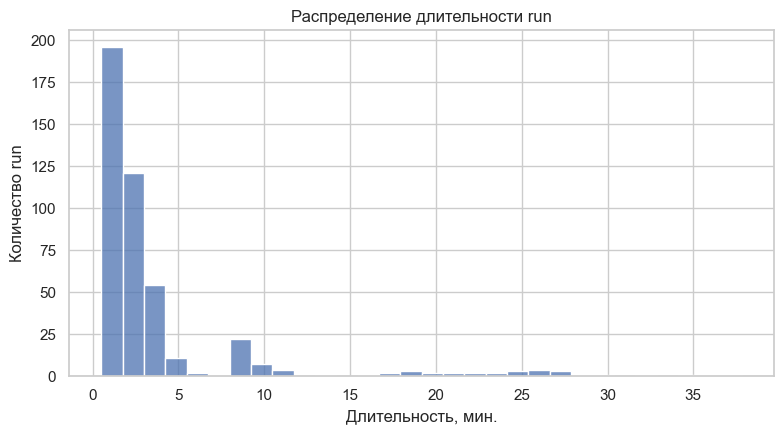

In [56]:
duration_plot_df = run_span_df.dropna(subset=["best_duration_sec"]).copy()
duration_plot_df["best_duration_min"] = duration_plot_df["best_duration_sec"] / 60

plt.figure(figsize=(8, 4.5))

sns.histplot(
    data=duration_plot_df,
    x="best_duration_min",
    bins=30,
    color="#4C72B0",
)

plt.title("Распределение длительности run")
plt.xlabel("Длительность, мин.")
plt.ylabel("Количество run")
plt.tight_layout()
plt.show()

### Медианное число окон на run

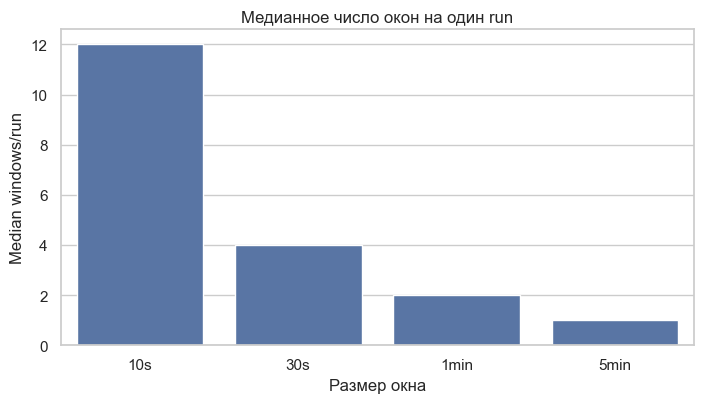

In [57]:
plt.figure(figsize=(7.2, 4.2))

sns.barplot(
    data=window_resolution_report_df,
    x="window_label",
    y="median_windows_per_run",
    color="#4C72B0",
)

plt.title("Медианное число окон на один run")
plt.xlabel("Размер окна")
plt.ylabel("Median windows/run")
plt.tight_layout()
plt.show()

### Доля single-window run

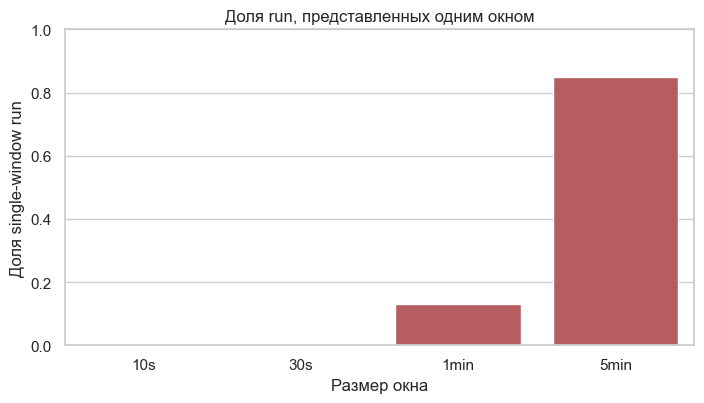

In [58]:
plt.figure(figsize=(7.2, 4.2))

sns.barplot(
    data=window_resolution_report_df,
    x="window_label",
    y="share_single_window",
    color="#C44E52",
)

plt.title("Доля run, представленных одним окном")
plt.xlabel("Размер окна")
plt.ylabel("Доля single-window run")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### График q95 числа окон

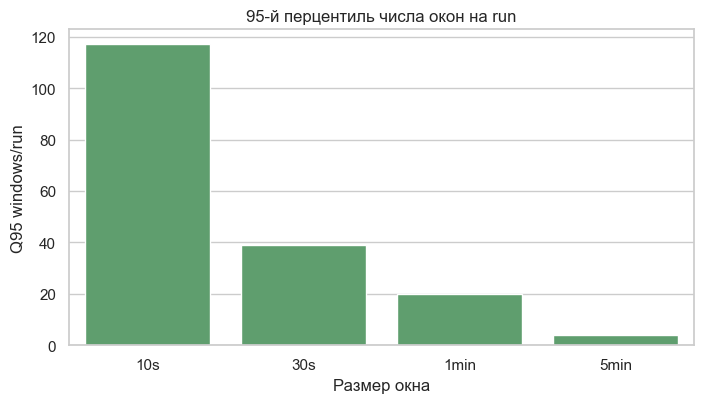

In [59]:
plt.figure(figsize=(7.2, 4.2))

sns.barplot(
    data=window_resolution_report_df,
    x="window_label",
    y="q95_windows_per_run",
    color="#55A868",
)

plt.title("95-й перцентиль числа окон на run")
plt.xlabel("Размер окна")
plt.ylabel("Q95 windows/run")
plt.tight_layout()
plt.show()

### Выводы по разделу

Анализ показывает, что при уменьшении размера окна число наблюдений на один запуск быстро возрастает. Для окна `10s` медианный run разбивается на существенно большее число сегментов, чем для окон `1min` и `5min`, что обеспечивает более детальное временное представление.

В то же время крупные окна приводят к заметной потере временной детализации. Для окна `5min` значительная часть запусков фактически представляется одним окном, поэтому такое разрешение подходит только как грубый макро-уровень описания.

Следовательно, в качестве кандидатов для multi-rate режима целесообразно использовать два масштаба:

- **micro-level:** `10s` и `30s`;
- **macro-level:** `1min` и `5min`.

Окончательный выбор рабочих окон должен быть подтверждён на следующем этапе исследования в notebook `02` по результатам построения и оценки признаков.

## 5. Аудит provenance

В этом разделе проверяется согласованность логовой и KPI-модальности на уровне `run_id`.

Для каждого запуска определяется статус связки источников:

- `STRICT` — доступны и raw log, и KPI-измерения;
- `LOG_ONLY` — доступен raw log, но отсутствует KPI-модальность;
- `KPI_ONLY` — доступны KPI-измерения, но отсутствует raw log;
- `MISSING_OR_AMBIGUOUS` — структура источников не позволяет однозначно определить статус.

Цель аудита — сформировать правило отбора запусков для следующего этапа исследования.

In [60]:
pairing_audit_df = run_inventory_df[
    [
        "workload",
        "scenario",
        "run_id",
        "scenario_type",
        "failure_family",
        "failure_mode",
        "has_mapred_log",
        "has_kpi_dir",
        "has_kpi_measurements",
        "has_parsed_labeled_workload",
        "strict_path_pair",
    ]
].copy()

conditions = [
    (
        pairing_audit_df["has_mapred_log"]
        & pairing_audit_df["has_kpi_dir"]
        & pairing_audit_df["has_kpi_measurements"]
    ),
    (
        pairing_audit_df["has_mapred_log"]
        & ~(
            pairing_audit_df["has_kpi_dir"]
            & pairing_audit_df["has_kpi_measurements"]
        )
    ),
    (
        ~pairing_audit_df["has_mapred_log"]
        & pairing_audit_df["has_kpi_dir"]
        & pairing_audit_df["has_kpi_measurements"]
    ),
]

choices = ["STRICT", "LOG_ONLY", "KPI_ONLY"]

pairing_audit_df["pair_status"] = np.select(
    conditions,
    choices,
    default="MISSING_OR_AMBIGUOUS",
)

pairing_audit_df["has_both_modalities"] = pairing_audit_df["pair_status"].eq("STRICT")

require_columns(
    pairing_audit_df,
    ["run_id", "pair_status", "has_both_modalities"],
    "pairing_audit_df",
)

status_counts_df = (
    pairing_audit_df
    .groupby("pair_status", as_index=False)
    .agg(runs=("run_id", "nunique"))
    .sort_values("runs", ascending=False)
    .reset_index(drop=True)
)

exceptions_df = (
    pairing_audit_df
    .loc[pairing_audit_df["pair_status"] != "STRICT"]
    .sort_values(["pair_status", "workload", "scenario"])
    .reset_index(drop=True)
)

strict_runs = int((pairing_audit_df["pair_status"] == "STRICT").sum())
non_strict_runs = int((pairing_audit_df["pair_status"] != "STRICT").sum())

if strict_runs + non_strict_runs != len(pairing_audit_df):
    raise ValueError(
        "Аудит provenance неконсистентен: сумма strict/non-strict "
        "не совпадает с числом run."
    )

### Распределение статусов связки

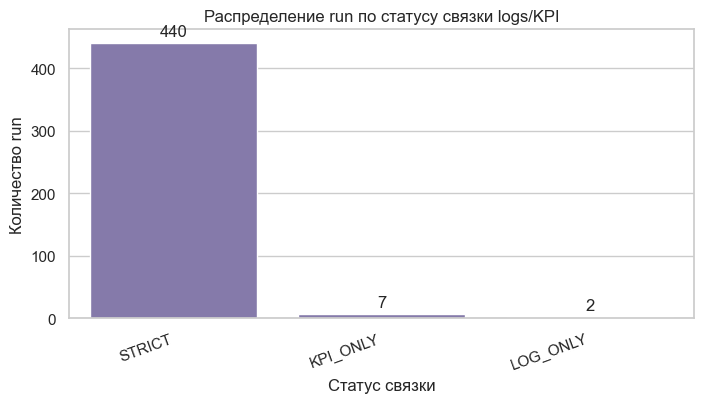

In [61]:
plt.figure(figsize=(7.2, 4.2))

ax = sns.barplot(
    data=status_counts_df,
    x="pair_status",
    y="runs",
    color="#8172B2",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Распределение run по статусу связки logs/KPI")
plt.xlabel("Статус связки")
plt.ylabel("Количество run")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Исключения из строгой связки

In [65]:
exceptions_view = exceptions_df[
    [
        "run_id",
        "pair_status",
        "scenario_type",
        "failure_family",
        "failure_mode",
    ]
]

display(exceptions_view)

,run_id,pair_status,scenario_type,failure_family,failure_mode
0,nweight/normal1,KPI_ONLY,normal,normal,normal
1,nweight/normal2,KPI_ONLY,normal,normal,normal
2,nweight/normal3,KPI_ONLY,normal,normal,normal
3,nweight/normal4,KPI_ONLY,normal,normal,normal
4,nweight/normal5,KPI_ONLY,normal,normal,normal
5,nweight/normal6,KPI_ONLY,normal,normal,normal
6,nweight/normal7,KPI_ONLY,normal,normal,normal
7,als/normal6,LOG_ONLY,normal,normal,normal
8,bayes/normal7,LOG_ONLY,normal,normal,normal


### Выводы по разделу

Аудит provenance показывает, что основная часть запусков имеет строгую связку логовой и KPI-модальности. Статус `STRICT` получили **440 run**, тогда как число non-STRICT запусков составляет **9 run**.

Все non-STRICT случаи представлены двумя типами несоответствий:

- `KPI_ONLY` — запуск присутствует в KPI-данных, но не имеет соответствующего raw log;
- `LOG_ONLY` — запуск имеет raw log, но не имеет соответствующей KPI-модальности.

Для дальнейшего анализа в notebook `02` базовым подмножеством следует считать только запуски со статусом `STRICT`. Non-STRICT случаи не удаляются из EDA, но должны быть исключены из построения признаков, где требуется одновременное наличие logs и KPI.

## 6. Финальная политика для notebook 02

В заключительном разделе фиксируются основные результаты EDA, которые влияют на следующий этап пайплайна.

Здесь не выполняется новая обработка данных. Раздел используется как handoff между первичным исследованием исходных данных и построением baseline-пайплайна в `02_multirate_baseline_raw_data.ipynb`.

In [66]:
missing_labeled_workloads = (
    dataset_inventory_df
    .loc[~dataset_inventory_df["has_labeled_csv"], "workload"]
    .tolist()
)

median_kpi_interval = (
    float(kpi_metadata_df["sample_median_interval_sec"].dropna().median())
    if not kpi_metadata_df.empty
    else np.nan
)

strict_runs = int(pairing_audit_df["pair_status"].eq("STRICT").sum())
non_strict_runs = int((~pairing_audit_df["pair_status"].eq("STRICT")).sum())

eda_snapshot_df = pd.DataFrame(
    [
        {
            "Показатель": "workloads",
            "Значение": int(len(dataset_inventory_df)),
        },
        {
            "Показатель": "runs / scenarios",
            "Значение": int(len(run_inventory_df)),
        },
        {
            "Показатель": "STRICT pairs",
            "Значение": strict_runs,
        },
        {
            "Показатель": "non-STRICT runs",
            "Значение": non_strict_runs,
        },
        {
            "Показатель": "workloads without labeled.csv",
            "Значение": (
                ", ".join(missing_labeled_workloads)
                if missing_labeled_workloads
                else "нет"
            ),
        },
        {
            "Показатель": "median KPI interval, sec",
            "Значение": (
                round(median_kpi_interval, 2)
                if np.isfinite(median_kpi_interval)
                else "n/a"
            ),
        },
    ]
)

display(eda_snapshot_df)

,Показатель,Значение
0,workloads,16
1,runs / scenarios,449
2,STRICT pairs,440
3,non-STRICT runs,9
4,workloads without labeled.csv,nweight
5,"median KPI interval, sec",1.0


### Итоговая политика передачи данных в notebook 02

По результатам EDA для следующего этапа фиксируется единая политика чтения, отбора и агрегации данных. Базовой единицей наблюдения считается отдельный запуск:

`run_id = workload / scenario`

Именно на уровне `run_id` должны выполняться объединение логов и KPI, построение временных окон, формирование признаков и последующее разбиение данных на train/test.

Логовая модальность должна обрабатываться с учётом различия между workload-level и run-level источниками. Файлы `parsed_log/labeled.csv` полезны для анализа шаблонов и контроля качества, однако они не содержат строгой привязки каждой строки к конкретному scenario. Поэтому run-level логовые признаки в notebook `02` следует строить из файлов `mapred_logs/<scenario>.log`.

KPI-модальность имеет иерархическую структуру `run_id / host / metric / series`, поэтому её не следует упрощать до одного плоского CSV. Для следующего этапа требуется отдельный series-aware parser, который сохраняет различия между хостами, метриками и внутренними размерностями KPI-файлов.

Анализ временного разрешения показал, что KPI-данные имеют регулярный шаг около одной секунды. Поэтому для multi-rate режима принимаются окна `10s`, `30s`, `1min` и `5min`. Основным micro-level вариантом является `10s`, окно `30s` используется как проверка устойчивости, `1min` — как macro-level context, а `5min` следует использовать осторожно из-за возможной потери временной детализации.

Основной supervised dataset должен строиться только на `STRICT`-запусках, где одновременно доступны raw logs и KPI-измерения. Non-STRICT случаи сохраняются в результатах EDA как часть аудита покрытия, но не должны попадать в основную обучающую выборку.

При разбиении данных необходимо контролировать риск leakage между близкими сценариями одного workload. Поэтому в notebook `02` следует использовать group-aware split и сохранять диагностические признаки покрытия: `log_available`, `kpi_available`, `has_both_modalities`, `pair_status`.

Таким образом, следующий notebook должен начинаться не с повторной инвентаризации `raw_data/`, а с применения зафиксированной политики отбора, чтения и агрегации данных.